In [1]:
import laspy
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import MultiPoint

In [2]:
number = 40

las_path = f"../data/processed_non_ground_sor/{number}kmh_pipeline_corridor_nonground_sor_ls.las"

las = laspy.read(las_path)


points = np.column_stack((
    np.array(las.x),
    np.array(las.y),
    np.array(las.z),
    np.array(las.intensity),
    np.array(las.return_number),
    np.array(las.red),
    np.array(las.green),
    np.array(las.blue),
))

print(points.shape)

(1531719, 8)


In [3]:
import numpy as np

x = np.array(las.x)
y = np.array(las.y)
z = np.array(las.z)
intensity = np.array(las.intensity, dtype=np.float32)
return_number = np.array(las.return_number, dtype=np.float32)
red = np.array(las.red, dtype=np.float32)
green = np.array(las.green, dtype=np.float32)
blue = np.array(las.blue, dtype=np.float32)

# Normalize non-spatial fields to comparable 0-1 range
intensity_norm = intensity / intensity.max() if intensity.max() > 0 else intensity
return_number_norm = return_number / return_number.max() if return_number.max() > 0 else return_number
red_norm = red / 65535.0
green_norm = green / 65535.0
blue_norm = blue / 65535.0

# Apply weights so spatial distance still dominates (these are your primary clustering signal)
spatial_weight = 1.0
color_weight = 0.3      # tune this — lower means color matters less
intensity_weight = 0.3   
return_weight = 0.3   

points = np.column_stack((
    x * spatial_weight,
    y * spatial_weight,
    z * spatial_weight,
    intensity_norm * intensity_weight,
    return_number_norm * return_weight,
    red_norm * color_weight,
    green_norm * color_weight,
    blue_norm * color_weight,
))

print(points.shape)

(1531719, 8)


In [5]:
def compute_local_features(points, k=20):
    from sklearn.neighbors import NearestNeighbors
    nbrs = NearestNeighbors(n_neighbors=k).fit(points)
    _, indices = nbrs.kneighbors(points)

    planarity = np.zeros(len(points))
    linearity = np.zeros(len(points))
    scatter = np.zeros(len(points))
    verticality = np.zeros(len(points))

    for i, neighbor_idx in enumerate(indices):
        neighborhood = points[neighbor_idx]
        cov = np.cov(neighborhood.T)
        eigvals, eigvecs = np.linalg.eigh(cov)
        order = np.argsort(eigvals)[::-1]
        eigvals = eigvals[order]
        eigvecs = eigvecs[:, order]
        l1, l2, l3 = eigvals + 1e-8

        planarity[i] = (l2 - l3) / l1
        linearity[i] = (l1 - l2) / l1     # <-- added
        scatter[i] = l3 / l1

        normal = eigvecs[:, 2]
        verticality[i] = 1 - abs(normal[2])

    return planarity, linearity, scatter, verticality

In [6]:
# --- Actually call it and store the results ---
planarity, linearity, scatter, verticality = compute_local_features(points, k=20)

print("planarity:", planarity.shape, planarity.min(), planarity.max())
print("linearity:", linearity.shape, linearity.min(), linearity.max())
print("scatter:", scatter.shape, scatter.min(), scatter.max())
print("verticality:", verticality.shape, verticality.min(), verticality.max())

planarity: (335700,) 0.0001556734339153451 0.9933425104095094
linearity: (335700,) 0.0017471551775820379 0.9996400478949921
scatter: (335700,) 1.8961602106315737e-05 0.910876399234108
verticality: (335700,) 2.0058303928927046e-07 0.9999998880830748


In [7]:
# Assume you already have these from compute_local_features()
# points: (N, 3), planarity: (N,), scatter: (N,), verticality: (N,)

# --- Build combined feature space ---
spatial_weight = 0.3    # keep XYZ as-is (in meters)
shape_weight = 0.3       # scale shape features up so they matter comparably to XYZ


features = np.column_stack([
    x * spatial_weight,
    y * spatial_weight,
    z * spatial_weight,
    intensity_norm * intensity_weight,
    return_number_norm * return_weight,
    red_norm * color_weight,
    green_norm * color_weight,
    blue_norm * color_weight,
    planarity * shape_weight,
    linearity * shape_weight,      
    scatter * shape_weight,
    verticality * shape_weight,
    ]) 

In [8]:
features.shape

(335700, 12)

In [4]:
from sklearn.cluster import DBSCAN

In [5]:
import sklearn
print(sklearn.__version__)

1.9.0


In [ ]:
db = DBSCAN(
    eps=0.3,
    min_samples=100,
    n_jobs=-1
)


labels = db.fit_predict(
    points
)


print("Clusters:", len(set(labels)))

In [20]:
print("First cluster ID:", labels.min())
print("Last cluster ID:", labels.max())

First cluster ID: -1
Last cluster ID: 87


In [21]:
print(points.shape)
print(labels.shape)

(335700, 8)
(335700,)


In [22]:
unique, counts = np.unique(
    labels,
    return_counts=True
)

cluster_info = sorted(
    zip(unique, counts),
    key=lambda x: x[1],
    reverse=True
)

for cluster, size in cluster_info[:20]:
    print(cluster, size)

77 90818
57 69802
78 56284
-1 31035
56 20628
0 20175
73 10177
58 7833
8 4646
32 1972
43 1550
65 1264
76 838
47 810
3 690
44 643
14 613
85 602
55 560
51 555


In [23]:
noise_points = np.sum(labels == -1)

print(
    "Noise points:",
    points
)

print(
    "Noise percentage:",
    noise_points / len(labels) * 100
)

Noise points: [[3.71528388e+05 5.64345074e+06 1.59780000e+02 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [3.71528391e+05 5.64345077e+06 1.59783000e+02 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [3.71528314e+05 5.64345071e+06 1.59788000e+02 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 ...
 [3.71530571e+05 5.64342366e+06 1.59943000e+02 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [3.71530098e+05 5.64342457e+06 1.60082000e+02 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [3.71530061e+05 5.64342396e+06 1.60116000e+02 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]]
Noise percentage: 9.244861483467382


In [24]:
sizes = counts[unique != -1]

print("Clusters < 50 points:",
      np.sum(sizes < 50))

print("Clusters < 100 points:",
      np.sum(sizes < 100))

Clusters < 50 points: 0
Clusters < 100 points: 3


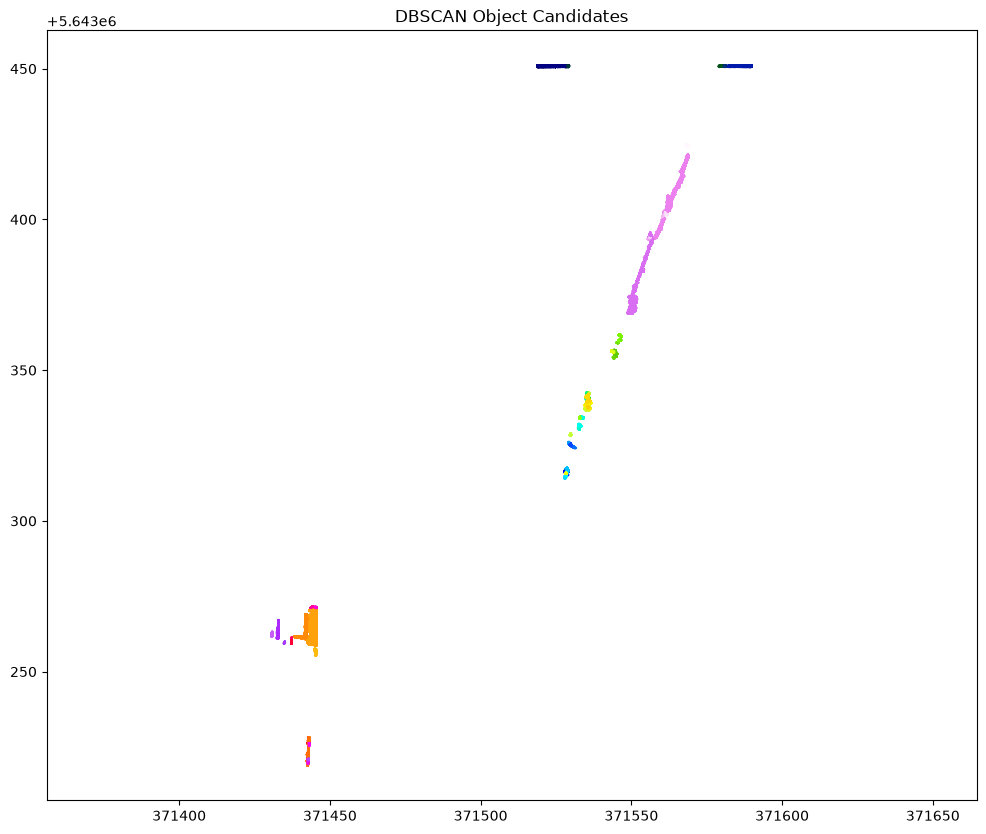

In [25]:
mask = labels != -1

fig, ax = plt.subplots(figsize=(12,10))

ax.scatter(
    points[mask,0],
    points[mask,1],
    c=labels[mask],
    s=0.5,
    cmap="gist_ncar"
)

ax.axis("equal")
ax.set_title("DBSCAN Object Candidates")

plt.show()


# Save limits
x_limits = ax.get_xlim()
y_limits = ax.get_ylim()

In [ ]:
cluster_id = 77

cluster_mask = labels == cluster_id


fig, ax = plt.subplots(figsize=(12,10))


# All points in grey
ax.scatter(
    points[mask,0],
    points[mask,1],
    s=0.2,
    c="lightgrey"
)


# Selected cluster
ax.scatter(
    points[cluster_mask,0],
    points[cluster_mask,1],
    s=1,
    c="red"
)


ax.set_xlim(x_limits)
ax.set_ylim(y_limits)

ax.axis("equal")
ax.set_title(f"Cluster {cluster_id} location")

plt.show()

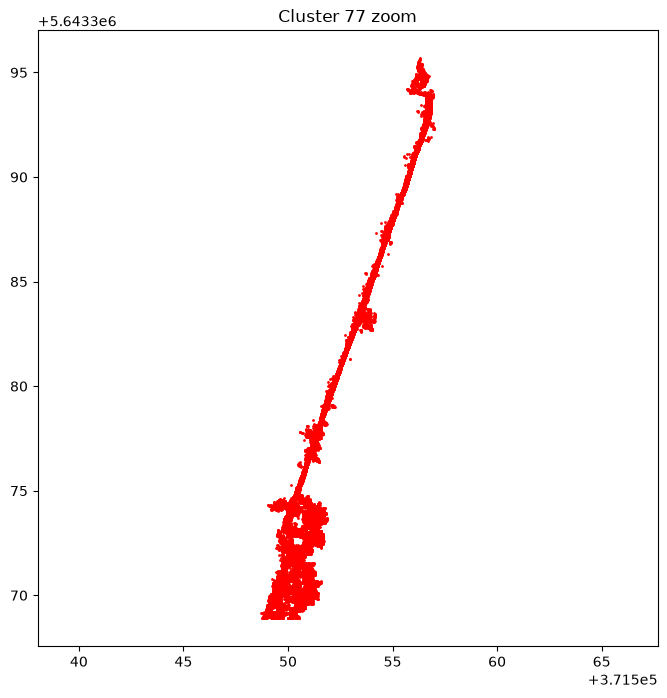

In [31]:
cluster_points = points[cluster_mask]


plt.figure(figsize=(8,8))

plt.scatter(
    cluster_points[:,0],
    cluster_points[:,1],
    s=1,
    c= 'red'
)


plt.axis("equal")
plt.title(f"Cluster {cluster_id} zoom")

plt.show()

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    cluster_points[:,0],
    cluster_points[:,2],
    s=1,
    c= 'red'
)

plt.xlabel("X")
plt.ylabel("Height Z")
plt.title(f"Cluster {cluster_id} Side View")

plt.show()

In [ ]:
print(
    "Height:",
    cluster_points[:,2].max()-cluster_points[:,2].min()
)